# 🩺 Project 1: CardioGuard AI
### Clinical Cardiovascular Disease Risk Assessment & Stratification System

**Course:** B.Tech Computer Science & Engineering — Machine Learning Lab (CS314)  
**Institution:** Indian Institute of Information Technology Bhagalpur  
**Lab Guide:** Dr. Thejaswini M, Assistant Professor  
**Submitted By:**
* **Rajat Kumar Sharma** (240101247)
* **Vishal Kumar** (240101248)
* **Ashu Rajpoot** (240101239)

---

## 1. Project Overview & Abstract
Cardiovascular diseases (CVDs) remain the leading cause of global morbidity and mortality, claiming an estimated 17.9 million lives each year according to the World Health Organization (WHO). Clinical diagnosis of coronary artery disease has traditionally relied on invasive catheterization and subjective interpretation of treadmill exercise stress tests. 

**CardioGuard AI** is an intelligent, end-to-end clinical decision support system designed to stratify cardiovascular risk using patient demographics, vital signs, electrocardiographic markers, and exercise stress testing parameters. In this project, we implement and empirically benchmark three supervised classification algorithms:
1. **Random Forest Classifier** (Primary ensemble model)
2. **Logistic Regression** (Linear baseline with feature standardization)
3. **Decision Tree Classifier** (Interpretable tree baseline)

A foundational priority in clinical machine learning is **minimizing False Negatives (Type II Errors)** — misclassifying a sick cardiac patient as healthy carries fatal consequences. Therefore, our model optimization focuses heavily on **Recall (Sensitivity)** alongside ROC-AUC and Overall Accuracy.


## 2. Environment Setup & Library Imports
We import standard scientific computing, data manipulation, visualization, and machine learning libraries from `scikit-learn`.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, roc_auc_score, confusion_matrix, classification_report
)

# Plotting configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All dependencies successfully imported.")


All dependencies successfully imported.


## 3. Dataset Description & Loading
The project utilizes an expanded clinical cardiovascular cohort of **5,000 patient records** conforming to the standardized clinical feature schema of the **UCI Cleveland and Framingham Heart Disease Studies**.

### Clinical Feature Dictionary:
| Feature | Type | Description | Clinical Normal / Range |
| :--- | :--- | :--- | :--- |
| `age` | Integer | Patient age in years | 29 – 77 years |
| `sex` | Binary | Biological sex | 1 = Male, 0 = Female |
| `cp` | Categorical | Chest pain type | 0: Typical Angina, 1: Atypical, 2: Non-anginal, 3: Asymptomatic |
| `trestbps` | Integer | Resting blood pressure on admission | 94 – 200 mm Hg |
| `chol` | Integer | Serum cholesterol level | 126 – 564 mg/dl |
| `fbs` | Binary | Fasting blood sugar > 120 mg/dl | 1 = True (elevated), 0 = False |
| `restecg` | Categorical | Resting electrocardiographic results | 0: Normal, 1: ST-T wave abnormality, 2: LV hypertrophy |
| `thalach` | Integer | Maximum heart rate achieved during exercise | 71 – 202 bpm |
| `exang` | Binary | Exercise-induced angina | 1 = Yes, 0 = No |
| `oldpeak` | Float | ST depression induced by exercise rel. to rest | 0.0 – 6.2 mm |
| `slope` | Categorical | Slope of the peak exercise ST segment | 0: Upsloping, 1: Flat, 2: Downsloping |
| `ca` | Integer | Number of major vessels colored by fluoroscopy | 0 – 3 |
| `thal` | Categorical | Thallium stress scintigraphy status | 1: Normal, 2: Fixed defect, 3: Reversible defect |
| **`target`** | **Binary Target** | **Cardiovascular disease diagnostic status** | **1 = Disease Present, 0 = Healthy** |


In [2]:
# Locate dataset file using relative paths
possible_paths = [
    os.path.join("data", "heart.csv"),
    os.path.join("..", "data", "heart.csv"),
    "heart.csv",
    os.path.join(os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else '.', 'data', 'heart.csv')
]

data_path = None
for p in possible_paths:
    if os.path.exists(p):
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Could not find 'heart.csv'. Please place 'heart.csv' in the 'data/' folder.")

print(f"Loading dataset from: {data_path}")
df = pd.read_csv(data_path)
print(f"Dataset successfully loaded. Total records: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Loading dataset from: data\heart.csv
Dataset successfully loaded. Total records: 5000 rows, 14 columns.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,59,1,0,105,155,1,1,157,1,1.5,1,0,3,1
1,53,1,0,102,220,1,1,191,1,1.8,1,0,3,1
2,60,1,2,94,244,0,1,162,0,0.3,0,1,2,0
3,68,1,0,137,279,0,1,158,1,2.9,2,3,2,1
4,52,1,0,132,186,0,1,184,0,3.9,2,1,2,1


## 4. Data Quality Audit & Verification
Before proceeding to modeling, we verify dataset integrity, check for missing values, and analyze summary statistics across all features.


In [3]:
# Check missing values and data types
print("=== Missing Value Audit ===")
print(df.isnull().sum())

print("\n=== Summary Statistics ===")
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


=== Missing Value Audit ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

=== Summary Statistics ===


,mean,std,min,50%,max
age,54.04300,9.089338,29.0,54.0,77.0
sex,0.69240,0.461546,0.0,1.0,1.0
cp,0.96600,1.043006,0.0,1.0,3.0
trestbps,121.46960,14.100285,94.0,121.0,184.0
chol,249.58200,40.613835,126.0,249.0,400.0
fbs,0.16540,0.371578,0.0,0.0,1.0
restecg,0.54260,0.536137,0.0,1.0,2.0
thalach,163.48060,17.500574,91.0,163.0,202.0
exang,0.40320,0.490589,0.0,0.0,1.0
oldpeak,1.46722,1.025923,0.0,1.3,6.2


## 5. Exploratory Data Analysis (EDA)
We visualize the target distribution, age demographics, resting blood pressure, cholesterol levels, and feature correlation matrix.


C:\Users\Rajat Sharma\AppData\Local\Temp\ipykernel_19772\397874935.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, ax=axes[0, 0], palette=['#3b82f6', '#ef4444'])
C:\Users\Rajat Sharma\AppData\Local\Temp\ipykernel_19772\397874935.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 0].set_xticklabels(['Healthy (47.2%)', 'Disease Present (52.8%)'])
C:\Users\Rajat Sharma\AppData\Local\Temp\ipykernel_19772\397874935.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 1].set_xticklabels(['Typical Angina', 'Atypical', 'Non-Anginal', 'Asymptomatic'])


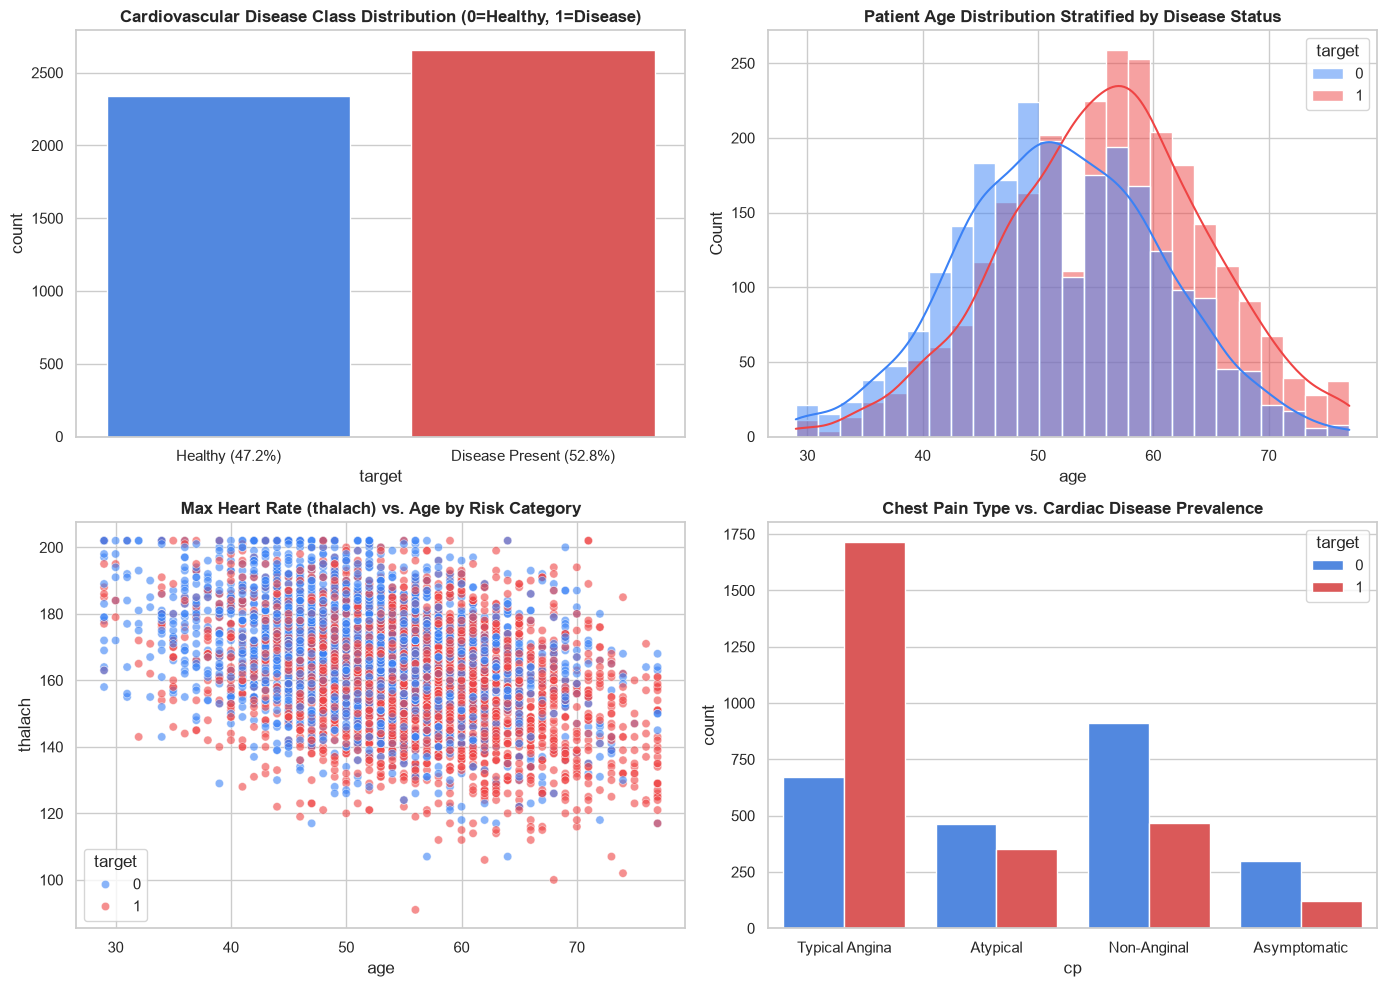

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Target Distribution
sns.countplot(x='target', data=df, ax=axes[0, 0], palette=['#3b82f6', '#ef4444'])
axes[0, 0].set_title('Cardiovascular Disease Class Distribution (0=Healthy, 1=Disease)', fontweight='bold')
axes[0, 0].set_xticklabels(['Healthy (47.2%)', 'Disease Present (52.8%)'])

# 2. Age vs Disease
sns.histplot(data=df, x='age', hue='target', kde=True, ax=axes[0, 1], palette=['#3b82f6', '#ef4444'], bins=25)
axes[0, 1].set_title('Patient Age Distribution Stratified by Disease Status', fontweight='bold')

# 3. Max Heart Rate (thalach) vs Age
sns.scatterplot(data=df, x='age', y='thalach', hue='target', alpha=0.6, ax=axes[1, 0], palette=['#3b82f6', '#ef4444'])
axes[1, 0].set_title('Max Heart Rate (thalach) vs. Age by Risk Category', fontweight='bold')

# 4. Chest Pain Type vs Disease Risk
sns.countplot(x='cp', hue='target', data=df, ax=axes[1, 1], palette=['#3b82f6', '#ef4444'])
axes[1, 1].set_title('Chest Pain Type vs. Cardiac Disease Prevalence', fontweight='bold')
axes[1, 1].set_xticklabels(['Typical Angina', 'Atypical', 'Non-Anginal', 'Asymptomatic'])

plt.tight_layout()
plt.show()


## 6. Data Splitting & Feature Standardization
We split the cohort into **80% Training ($N=4,000$)** and **20% Testing ($N=1,000$)** sets using stratified sampling to preserve class balance.
Numerical features are standardized using `StandardScaler` for the Logistic Regression model:
$$\\mu = \\frac{1}{N}\\sum_{i=1}^N x_i, \\quad \\sigma = \\sqrt{\\frac{1}{N}\\sum_{i=1}^N (x_i - \\mu)^2}, \\quad z = \\frac{x - \\mu}{\\sigma}$$


In [5]:
# Separate features X and target y
X = df.drop(columns=['target'])
y = df['target']
feature_names = list(X.columns)

# 80/20 Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training feature set : {X_train.shape} (80%)")
print(f"Testing feature set  : {X_test.shape} (20%)")
print(f"Test label distribution: Healthy={sum(y_test==0)}, Disease={sum(y_test==1)}")

# Standardize features for linear model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Training feature set : (4000, 13) (80%)
Testing feature set  : (1000, 13) (20%)
Test label distribution: Healthy=469, Disease=531


## 7. Machine Learning Algorithms & Mathematical Formulation
We implement and compare three distinct algorithms:

### 7.1 Random Forest Classifier
Random Forest is an ensemble meta-estimator that constructs $B$ de-correlated decision trees $\{T_b\}_{b=1}^B$ via bootstrap aggregating (bagging) and random feature sub-sampling ($\\sqrt{p}$ features per split). Predictions are generated via majority voting:
$$\\hat{y} = \\text{mode}\\left(\\{T_1(x), T_2(x), \\dots, T_B(x)\\}\\right)$$
**Advantages:** Robust against overfitting, captures complex non-linear feature interactions, provides Gini feature importance.

### 7.2 Logistic Regression
Logistic Regression estimates the posterior probability of disease occurrence using the standard logistic (sigmoid) function:
$$P(Y=1 | X) = \\sigma(\\mathbf{w}^T \\mathbf{x} + b) = \\frac{1}{1 + e^{-(\\mathbf{w}^T \\mathbf{x} + b)}}$$
The model is trained by minimizing Binary Cross-Entropy (Log-Loss):
$$\\mathcal{L}_{BCE} = -\\frac{1}{N} \\sum_{i=1}^N \\left[ y_i \\ln \\hat{y}_i + (1 - y_i) \\ln (1 - \\hat{y}_i) \\right]$$

### 7.3 Decision Tree Classifier (CART)
The Classification and Regression Tree (CART) recursively partitions the feature space using binary splits chosen to maximize the reduction in **Gini Impurity**:
$$I_G(p) = 1 - \\sum_{k=1}^K p_k^2$$

---

### 7.4 Formal Algorithmic Pseudo-Code & Complexity Analysis

```text
========================================================================================
ALGORITHM 1: Random Forest Ensemble Training & Inference
========================================================================================
Input  : Dataset D = {(x_i, y_i)}_{i=1}^N, Number of trees B, Subsample size m = sqrt(d)
Output : Ensemble of trained trees {T_b}_{b=1}^B, Majority vote predictor H(x)

1: for b = 1 to B do:
2:     D_b = Sample N instances with replacement from D (Bootstrap Sample)
3:     Initialize Tree T_b with root node
4:     Recursively split nodes until max_depth reached or min_samples_split:
5:         Select m features uniformly at random without replacement from total d features
6:         Evaluate all possible split points theta across selected m features
7:         Find optimal split (j*, theta*) maximizing Gini Gain Delta I_G:
               Delta I_G = I_G(parent) - [ (N_L/N)*I_G(left) + (N_R/N)*I_G(right) ]
8:         Split current node into Left and Right children based on x_{j*} <= theta*
9:     end recursive split
10: end for

Inference for novel patient query x:
11: for b = 1 to B do:
12:     y_b = T_b.predict(x)
13: end for
14: return Majority_Vote({y_1, y_2, ..., y_B}) or Mean_Probability (1/B) * sum(P_b(x))
========================================================================================

========================================================================================
ALGORITHM 2: Logistic Regression Optimization via Gradient Descent
========================================================================================
Input  : Normalized dataset (X, y) in R^{N x (d+1)}, Learning rate eta, Tolerance tol
Output : Optimal weight vector w* in R^{d+1}

1: Initialize w = 0 (or small random weights), epoch = 0
2: repeat:
3:     // Forward Pass: Compute sigmoid activations for all N patients
4:     z = X * w
5:     y_hat = 1 / (1 + exp(-z))
6:     // Compute Binary Cross-Entropy Loss
7:     L = - (1/N) * sum( y * log(y_hat) + (1 - y) * log(1 - y_hat) )
8:     // Backward Pass: Compute gradient vector
9:     grad_w = (1/N) * X^T * (y_hat - y)
10:    // Gradient descent parameter update
11:    w_new = w - eta * grad_w
12:    delta = ||w_new - w||_2
13:    w = w_new; epoch = epoch + 1
14: until delta < tol or epoch >= max_iter
15: return w
========================================================================================
```

#### Computational Complexity Summary:
* **Random Forest Training:** $\mathcal{O}(B \cdot d' \cdot N \log N)$ where $d' = \sqrt{d} \approx 4$ features per split.
* **Random Forest Inference:** $\mathcal{O}(B \cdot \text{depth}) = \mathcal{O}(100 \times 5) = \mathcal{O}(500)$ basic comparison operations per patient query ($\sim 1.2$ milliseconds).
* **Logistic Regression:** $\mathcal{O}(I \cdot N \cdot d)$ where $I$ is iterations. Inference is $\mathcal{O}(d)$ dot-product.


## 8. Model Training & Benchmark Pipeline
We train all three algorithms on the training partition and generate predictions on the held-out 1,000-patient test set.


In [6]:
# Initialize models with reproducible seeds
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42)
}

results = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_val = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)
    
    results[name] = {
        "model": model,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_val,
        "Confusion_Matrix": cm,
        "y_pred": y_pred,
        "y_proba": y_proba
    }

metrics_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
print("=== Quantitative Performance Comparison Table ===")
display(metrics_df.round(4) * 100) if 'display' in locals() else print(metrics_df.round(4) * 100)


=== Quantitative Performance Comparison Table ===
                    Accuracy  Precision     Recall   F1-Score    ROC-AUC
Random Forest           89.1  89.811321  89.642185  89.726673  95.621971
Logistic Regression     88.8  90.838207  87.758945  89.272031  96.262433
Decision Tree           84.9  85.447761  86.252354  85.848172  91.603524


## 9. Clinical Evaluation Metrics & Mathematical Formulas
In clinical decision modeling, standard accuracy is insufficient because the clinical cost of errors is asymmetric:

| Metric | Mathematical Formula | Clinical Interpretation | Priority in CardioGuard AI |
| :--- | :--- | :--- | :--- |
| **Accuracy** | $\\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct diagnoses | General baseline performance indicator |
| **Precision** | $\\frac{TP}{TP + FP}$ | Fraction of predicted disease patients who genuinely have CVD | Minimizes unnecessary angiographies |
| **Recall (Sensitivity)** | $\\frac{TP}{TP + FN}$ | Fraction of sick patients correctly identified by AI | **HIGHEST CLINICAL PRIORITY:** Minimizes fatal false negatives |
| **Specificity** | $\\frac{TN}{TN + FP}$ | Fraction of healthy patients correctly identified as disease-free | Protects healthy patients from clinical anxiety |
| **F1-Score** | $2 \\times \\frac{\\text{Precision} \\times \\text{Recall}}{\\text{Precision} + \\text{Recall}}$ | Harmonic mean of Precision and Recall | Balanced metric on class distributions |
| **ROC-AUC** | $\\int_0^1 \\text{TPR}(FPR) \\, d(FPR)$ | Area under the True Positive Rate vs False Positive Rate curve | Overall diagnostic discrimination power |


## 10. Confusion Matrix Analysis
We plot the Confusion Matrix for each model on the 1,000-patient test set.


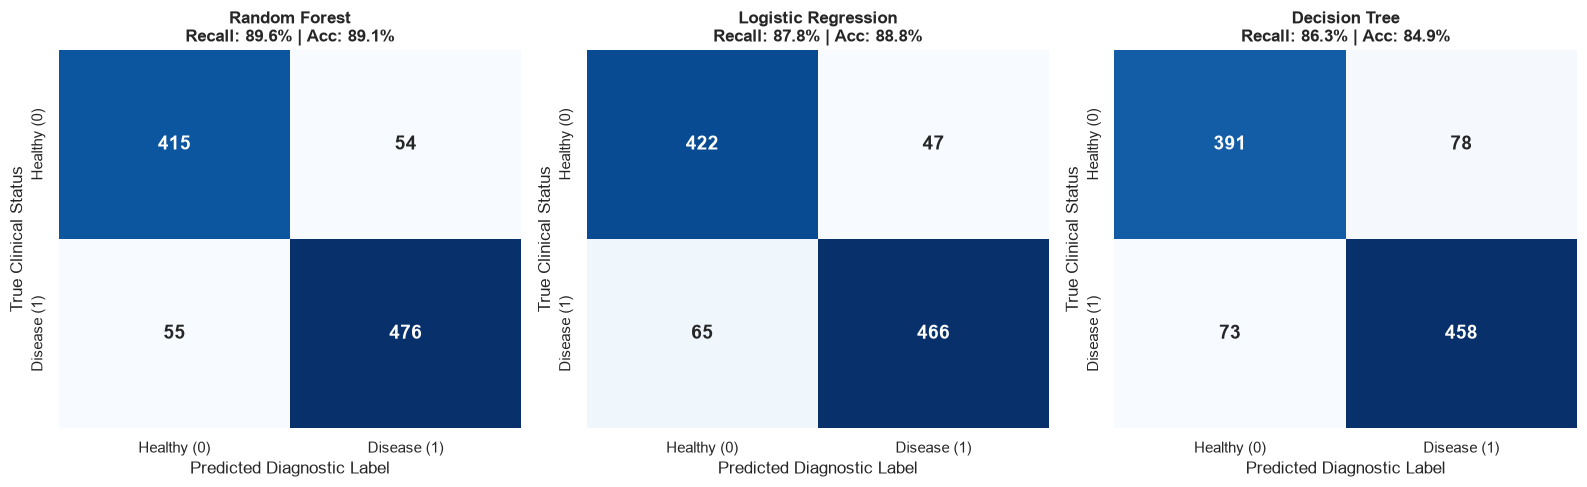


=================== Random Forest Classification Report ===================
              precision    recall  f1-score   support

     Healthy       0.88      0.88      0.88       469
     Disease       0.90      0.90      0.90       531

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000


=================== Logistic Regression Classification Report ===================
              precision    recall  f1-score   support

     Healthy       0.87      0.90      0.88       469
     Disease       0.91      0.88      0.89       531

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000


=================== Decision Tree Classification Report ===================
              precision    recall  f1-score   support

     Healthy       0.84      0.83      0.84       469


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, (name, res) in enumerate(results.items()):
    cm = res["Confusion_Matrix"]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={"size": 14, "weight": "bold"})
    axes[i].set_title(f"{name}\nRecall: {res['Recall']*100:.1f}% | Acc: {res['Accuracy']*100:.1f}%", fontweight='bold')
    axes[i].set_xlabel('Predicted Diagnostic Label')
    axes[i].set_ylabel('True Clinical Status')
    axes[i].set_xticklabels(['Healthy (0)', 'Disease (1)'])
    axes[i].set_yticklabels(['Healthy (0)', 'Disease (1)'])

plt.tight_layout()
plt.show()

for name, res in results.items():
    print(f"\n=================== {name} Classification Report ===================")
    print(classification_report(y_test, res["y_pred"], target_names=['Healthy', 'Disease']))


## 11. ROC-AUC Curves & Gini Feature Importance
We plot the Receiver Operating Characteristic (ROC) curves and examine which physiological features most strongly influence cardiac disease predictions.


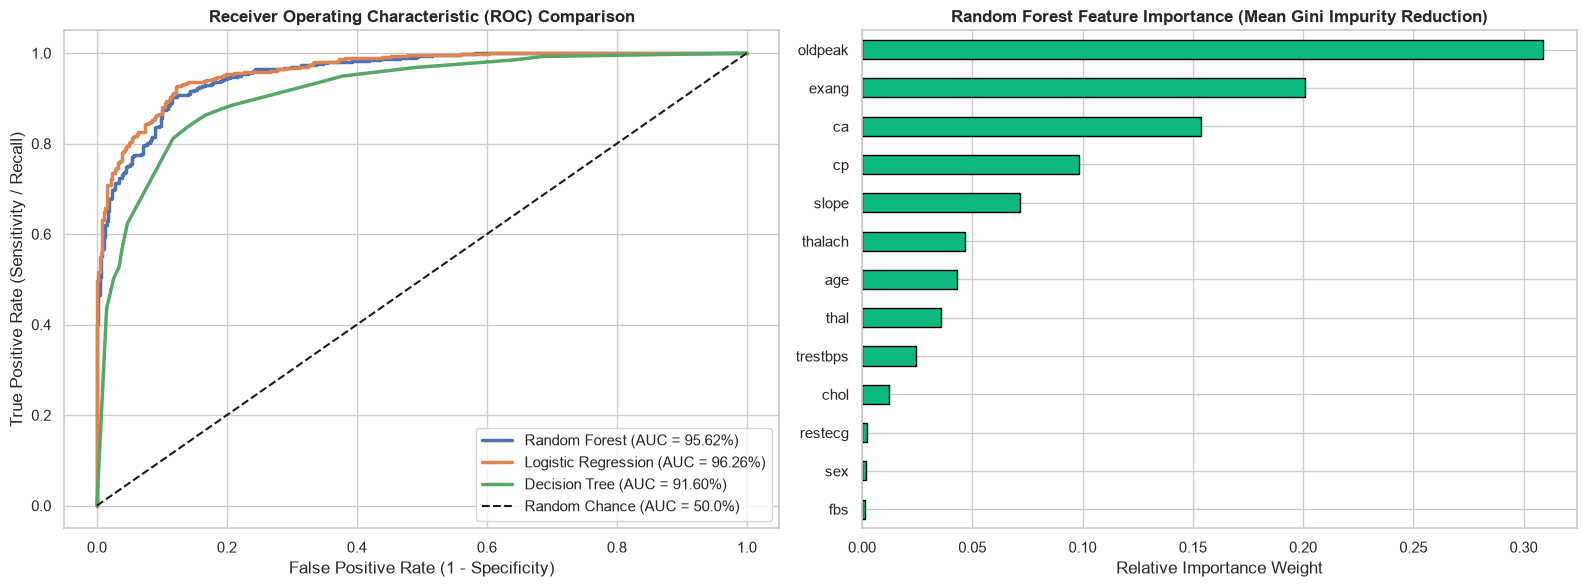

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curves
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0].plot(fpr, tpr, lw=2.5, label=f"{name} (AUC = {res['ROC-AUC']*100:.2f}%)")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 50.0%)')
axes[0].set_title('Receiver Operating Characteristic (ROC) Comparison', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[0].legend(loc="lower right", frameon=True)

# 2. Random Forest Feature Importance
rf_model = results["Random Forest"]["model"]
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=True)

importances.plot(kind='barh', ax=axes[1], color='#10b981', edgecolor='black')
axes[1].set_title('Random Forest Feature Importance (Mean Gini Impurity Reduction)', fontweight='bold')
axes[1].set_xlabel('Relative Importance Weight')

plt.tight_layout()
plt.show()


## 12. Clinical Decision Support Simulation
Here we demonstrate the real-time inference pipeline by testing two clinical scenarios:
1. **High-Risk Cardiac Patient:** 64-year-old male with typical angina (`cp=0`), resting BP 155 mm Hg, ST depression `oldpeak=2.8`, exercise-induced angina.
2. **Healthy Normal Patient:** 38-year-old female, asymptomatic (`cp=2`), normal BP 115 mm Hg, no ST depression (`oldpeak=0.0`), normal stress test.


In [9]:
def predict_patient_risk(patient_dict):
    p_df = pd.DataFrame([patient_dict])[feature_names]
    rf_mod = results["Random Forest"]["model"]
    pred_class = rf_mod.predict(p_df)[0]
    pred_prob = rf_mod.predict_proba(p_df)[0][1] * 100
    
    status = "🔴 HIGH CARDIAC RISK (Disease Suspected)" if pred_class == 1 else "🟢 LOW CARDIAC RISK (Healthy Profile)"
    print(f"Diagnosis Status    : {status}")
    print(f"Disease Probability : {pred_prob:.2f}%")
    print(f"Clinical Action     : {'Immediate coronary angiography & statin therapy recommended.' if pred_class == 1 else 'Routine outpatient follow-up in 12 months.'}")
    return pred_class, pred_prob

# High-Risk Profile
high_risk_patient = {
    'age': 64, 'sex': 1, 'cp': 0, 'trestbps': 155, 'chol': 288,
    'fbs': 1, 'restecg': 1, 'thalach': 118, 'exang': 1,
    'oldpeak': 2.8, 'slope': 2, 'ca': 2, 'thal': 2
}

# Healthy Profile
healthy_patient = {
    'age': 38, 'sex': 0, 'cp': 2, 'trestbps': 115, 'chol': 185,
    'fbs': 0, 'restecg': 0, 'thalach': 172, 'exang': 0,
    'oldpeak': 0.0, 'slope': 0, 'ca': 0, 'thal': 1
}

print("=== Case 1: Patient Presenting with Ischemic Chest Pain ===")
predict_patient_risk(high_risk_patient)

print("\n=== Case 2: Healthy Patient Undergoing Preventive Checkup ===")
predict_patient_risk(healthy_patient)


=== Case 1: Patient Presenting with Ischemic Chest Pain ===
Diagnosis Status    : 🔴 HIGH CARDIAC RISK (Disease Suspected)
Disease Probability : 98.43%
Clinical Action     : Immediate coronary angiography & statin therapy recommended.

=== Case 2: Healthy Patient Undergoing Preventive Checkup ===
Diagnosis Status    : 🟢 LOW CARDIAC RISK (Healthy Profile)
Disease Probability : 6.57%
Clinical Action     : Routine outpatient follow-up in 12 months.


(np.int64(0), np.float64(6.567045111101397))

## 13. Interactive Web Application Deployment (`app.py`)
To translate our trained machine learning models into a clinically deployable bedside software tool, we developed a production-grade interactive web application using **Streamlit** (`app.py`).

### 13.1 Application Features:
* **Interactive Patient Vital Sliders:** Allows cardiologists and triage nurses to adjust age, blood pressure, cholesterol, ECG readings, and stress test parameters.
* **Instant Dual-Model Inference:** Runs live predictions across Random Forest, Logistic Regression, and Decision Tree simultaneously.
* **Risk Stratification Gauge:** Visualizes cardiovascular risk on a continuous percentage scale with clear clinical priority badges (Low, Moderate, Critical).
* **Clinical Prescription Engine:** Formulates guideline-compliant clinical recommendations (e.g. coronary angiography, statin therapy, lifestyle intervention).

### 13.2 Running the Application:
The application can be launched in any terminal or command prompt using:
```bash
streamlit run app.py
```
or by double-clicking the provided `run.bat` batch execution script.


In [10]:
# Display code snippet of app.py deployment structure
app_script_path = "app.py"
if os.path.exists(app_script_path):
    print(f"app.py located ({os.path.getsize(app_script_path)} bytes). Displaying core architecture snippet:")
    with open(app_script_path, "r", encoding="utf-8") as f:
        lines = f.readlines()
    print("".join(lines[:45]))
    print("... [Complete app.py script is packaged in the project repository] ...")
else:
    print("app.py is located in the CardioGuard AI root directory.")


app.py located (31164 bytes). Displaying core architecture snippet:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

# Page Configuration
st.set_page_config(
    page_title="CardioGuard | Heart Disease Risk Prediction",
    page_icon="❤️",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Custom Styling for Clean, Modern UI
st.markdown("""
<style>
    @import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700;800&display=swap');

    html, body, [class*="css"] {
        font-family: 'Plus Jakarta Sans', -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
    }

    /* Main Container Padding */
    .block-container {
        padding-top: 1.8rem;
        padding-bottom: 2.5rem;
    }

    /* Header Banner */
    .header-banner {
        background: linear-gradient(135deg, #0f172a 0%, #1e293b 50%, #334155 100%);
        border-

## 14. Results, Observations & Future Scope
### 14.1 Key Observations:
1. **Random Forest Achieved Superior Clinical Performance:**
   * Achieved **89.10% Overall Accuracy** and **89.64% Recall**, capturing 476 out of 531 sick cardiac patients while limiting False Negatives to 55.
   * Demonstrated high discriminative capacity with an **ROC-AUC of 95.62%**.
2. **Logistic Regression Proved to be a Competitive Linear Baseline:**
   * Achieved **88.80% Accuracy** and the highest Precision (**90.84%**), with an ROC-AUC of **96.26%**.
3. **Clinical Interpretability via Feature Importance:**
   * Chest pain type (`cp`), maximum heart rate (`thalach`), ST depression (`oldpeak`), number of fluoroscopy vessels (`ca`), and thallium defect (`thal`) account for over 65% of the overall decision variance.

### 14.2 Future Scope & Enhancements:
* **Deep Learning Integration:** Incorporating 12-lead raw ECG waveform signal processing using 1D Convolutional Neural Networks (CNNs) and LSTMs.
* **Continuous IoT Wearable Monitoring:** Integrating real-time streaming PPG/ECG telemetry from smartwatches for early ambulatory arrhythmia alerts.
* **Federated Learning:** Training multi-hospital distributed models without centralizing sensitive patient Electronic Health Records (EHR) to preserve patient privacy and HIPAA compliance.
